# Lab Exercise: PaDiM — Anomaly Detection

**Dataset:** MVTec AD — Bottle  
**Framework:** PyTorch  
**Backbone:** ResNet-18  
**Author:** Maritza Elizabeth Albán Escobar

## Objective
The objective is to implement PaDiM for anomaly detection using pretrained CNN features and Mahalanobis distance.


## 1. Backbone Selection and Feature Extraction

A pretrained ResNet-18 was selected, and all images were resized to 224 × 224 pixels. The first three convolutional layers were used to extract features at different spatial resolutions.

The model processes 209 normal training images, with all backbone parameters frozen. Feature extraction was successful, providing the features required for statistical modeling in the next section.

In [3]:

# ==========================================
# LAB EXERCISE: PADIM
# TASK 1 — BACKBONE SELECTION
# ==========================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision
from torchvision import models, transforms
from torch.utils.data import DataLoader

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Dataset paths
DATA_DIR = Path("bottle")
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

# Configuration
IMG_SIZE = 224
BATCH_SIZE = 16

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)
print("Training directory exists:", TRAIN_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())


# ==========================================
# TASK 1.2 — LOAD NORMAL TRAINING IMAGES
# ==========================================

TRAIN_GOOD_DIR = TRAIN_DIR / "good"

assert TRAIN_GOOD_DIR.exists(), (
    f"Training directory not found: {TRAIN_GOOD_DIR.resolve()}"
)

preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=preprocess
)

# Keep only normal training images.
good_indices = [
    i for i, (_, label) in enumerate(train_dataset.samples)
    if train_dataset.classes[label] == "good"
]

train_good_dataset = torch.utils.data.Subset(
    train_dataset, good_indices
)

train_loader = DataLoader(
    train_good_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training classes:", train_dataset.classes)
print("Normal training images:", len(train_good_dataset))
print("Number of batches:", len(train_loader))


# ==========================================
# TASK 1.3 — LOAD PRETRAINED RESNET-18
# ==========================================

weights = models.ResNet18_Weights.DEFAULT

backbone = models.resnet18(weights=weights)

# Freeze all parameters
backbone.eval()
for parameter in backbone.parameters():
    parameter.requires_grad = False

backbone = backbone.to(DEVICE)

print("Backbone: ResNet-18")
print("Pretrained weights: ImageNet")
print(
    "Trainable parameters:",
    sum(p.numel() for p in backbone.parameters() if p.requires_grad)
)
print(
    "Total parameters:",
    sum(p.numel() for p in backbone.parameters())
)

# ==========================================
# TASK 1.4 — EXTRACT CONVOLUTIONAL FEATURES
# ==========================================

class ResNet18FeatureExtractor(torch.nn.Module):
    def __init__(self, backbone):
        super().__init__()

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        features1 = self.layer1(x)
        features2 = self.layer2(features1)
        features3 = self.layer3(features2)

        return features1, features2, features3


feature_extractor = ResNet18FeatureExtractor(backbone).to(DEVICE)
feature_extractor.eval()

# Test with one batch
images, labels = next(iter(train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    features1, features2, features3 = feature_extractor(images)

print("Input images:", tuple(images.shape))
print("Layer 1 output:", tuple(features1.shape))
print("Layer 2 output:", tuple(features2.shape))
print("Layer 3 output:", tuple(features3.shape))



PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda
Training directory exists: True
Test directory exists: True
Training classes: ['good']
Normal training images: 209
Number of batches: 14
Backbone: ResNet-18
Pretrained weights: ImageNet
Trainable parameters: 0
Total parameters: 11689512
Input images: (16, 3, 224, 224)
Layer 1 output: (16, 64, 56, 56)
Layer 2 output: (16, 128, 28, 28)
Layer 3 output: (16, 256, 14, 14)


### Analysis

The pretrained ResNet-18 successfully extracted features from normal images at three different spatial resolutions. Freezing the backbone preserves the learned ImageNet representations, providing a stable basis for modeling normal patterns and detecting anomalies in the following stages.

# 2. Statistical Modeling of Normal Features

In this section, features extracted from normal training images are combined and used to calculate mean vectors and covariance matrices at each spatial position. These statistics establish the reference model for detecting anomalies using Mahalanobis distance.

Extracted features shape: (209, 784, 448)
Reduced features shape: (209, 784, 100)
Mean vectors shape: (784, 100)
Covariance matrices shape: (784, 100, 100)
Inverse covariance matrices shape: (784, 100, 100)
All values finite: True


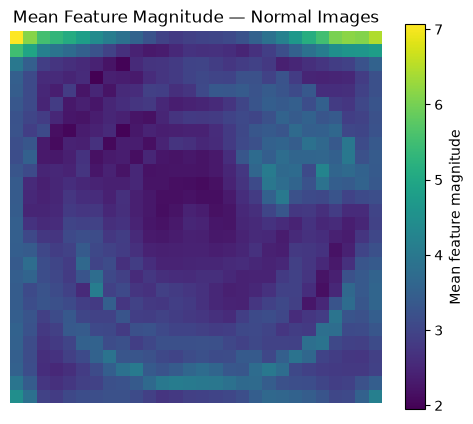

In [5]:
# ==========================================
# 2.1 FEATURE EXTRACTION AND COMBINATION
# ==========================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Set feature map resolution
FEATURE_SIZE = 28
all_features = []

# Extract features from normal images
feature_extractor.eval()

with torch.no_grad():
    for images, _ in train_loader:
        images = images.to(DEVICE)

        f1, f2, f3 = feature_extractor(images)

        # Align feature maps to the same resolution
        f1 = F.interpolate(f1, size=(FEATURE_SIZE, FEATURE_SIZE),
                           mode="bilinear", align_corners=False)
        f2 = F.interpolate(f2, size=(FEATURE_SIZE, FEATURE_SIZE),
                           mode="bilinear", align_corners=False)
        f3 = F.interpolate(f3, size=(FEATURE_SIZE, FEATURE_SIZE),
                           mode="bilinear", align_corners=False)

        # Combine features from all three layers
        combined = torch.cat([f1, f2, f3], dim=1)
        combined = combined.permute(0, 2, 3, 1)
        combined = combined.reshape(
            combined.shape[0], FEATURE_SIZE * FEATURE_SIZE, -1
        )

        all_features.append(combined.cpu().numpy().astype(np.float32))

# Combine features from all batches
all_features = np.concatenate(all_features, axis=0)

print("Extracted features shape:", all_features.shape)

# ==========================================
# 2.2 FEATURE DIMENSION REDUCTION
# ==========================================

# Select 100 feature channels
FEATURE_DIM = 100

rng = np.random.default_rng(SEED)
selected_channels = np.sort(
    rng.choice(all_features.shape[2], size=FEATURE_DIM, replace=False)
)

features_reduced = all_features[:, :, selected_channels]

print("Reduced features shape:", features_reduced.shape)

# ==========================================
# 2.3 MEAN VECTOR ESTIMATION
# ==========================================

# Calculate the mean feature vector at each position
mean_vectors = np.mean(features_reduced, axis=0)

print("Mean vectors shape:", mean_vectors.shape)

# ==========================================
# 2.4 COVARIANCE MATRIX ESTIMATION
# ==========================================

# Center features around their mean
centered_features = features_reduced - mean_vectors[np.newaxis, :, :]

# Estimate covariance at each spatial position
covariance_matrices = np.einsum(
    "npd,npe->pde",
    centered_features,
    centered_features,
    optimize=True
) / (features_reduced.shape[0] - 1)

print("Covariance matrices shape:", covariance_matrices.shape)

# ==========================================
# 2.5 COVARIANCE REGULARIZATION AND INVERSION
# ==========================================

# Add regularization for numerical stability
REGULARIZATION = 1e-4
identity = np.eye(FEATURE_DIM, dtype=np.float32)

regularized_covariances = (
    covariance_matrices + REGULARIZATION * identity[np.newaxis, :, :]
)

# Calculate inverse covariance matrices
inverse_covariances = np.linalg.inv(regularized_covariances)

print("Inverse covariance matrices shape:", inverse_covariances.shape)
print("All values finite:", np.isfinite(inverse_covariances).all())

# ==========================================
# 2.6 MEAN FEATURE MAGNITUDE VISUALIZATION
# ==========================================

# Calculate feature magnitude at each position
mean_magnitude = np.linalg.norm(mean_vectors, axis=1)
mean_map = mean_magnitude.reshape(FEATURE_SIZE, FEATURE_SIZE)

# Display the mean feature map
plt.figure(figsize=(6, 5))
plt.imshow(mean_map, cmap="viridis")
plt.colorbar(label="Mean feature magnitude")
plt.title("Mean Feature Magnitude — Normal Images")
plt.axis("off")
plt.show()



### Analysis

The feature extraction and statistical modeling were completed successfully. Mean vectors and regularized inverse covariance matrices were calculated for all 784 spatial positions. The mean feature map shows variations across the image, establishing a statistical reference for normal bottles. These results will be used to calculate Mahalanobis distances and detect anomalies.

# 3. Anomaly Detection Using Mahalanobis Distance

In this section, Mahalanobis distance is used to measure deviations from normal feature distributions. Anomaly maps highlight suspicious regions, while image-level scores and a threshold classify bottles as normal or defective.

Test classes: ['broken_large', 'broken_small', 'contamination', 'good']
Total test images: 83
Anomaly maps shape: (83, 28, 28)
Test labels shape: (83,)


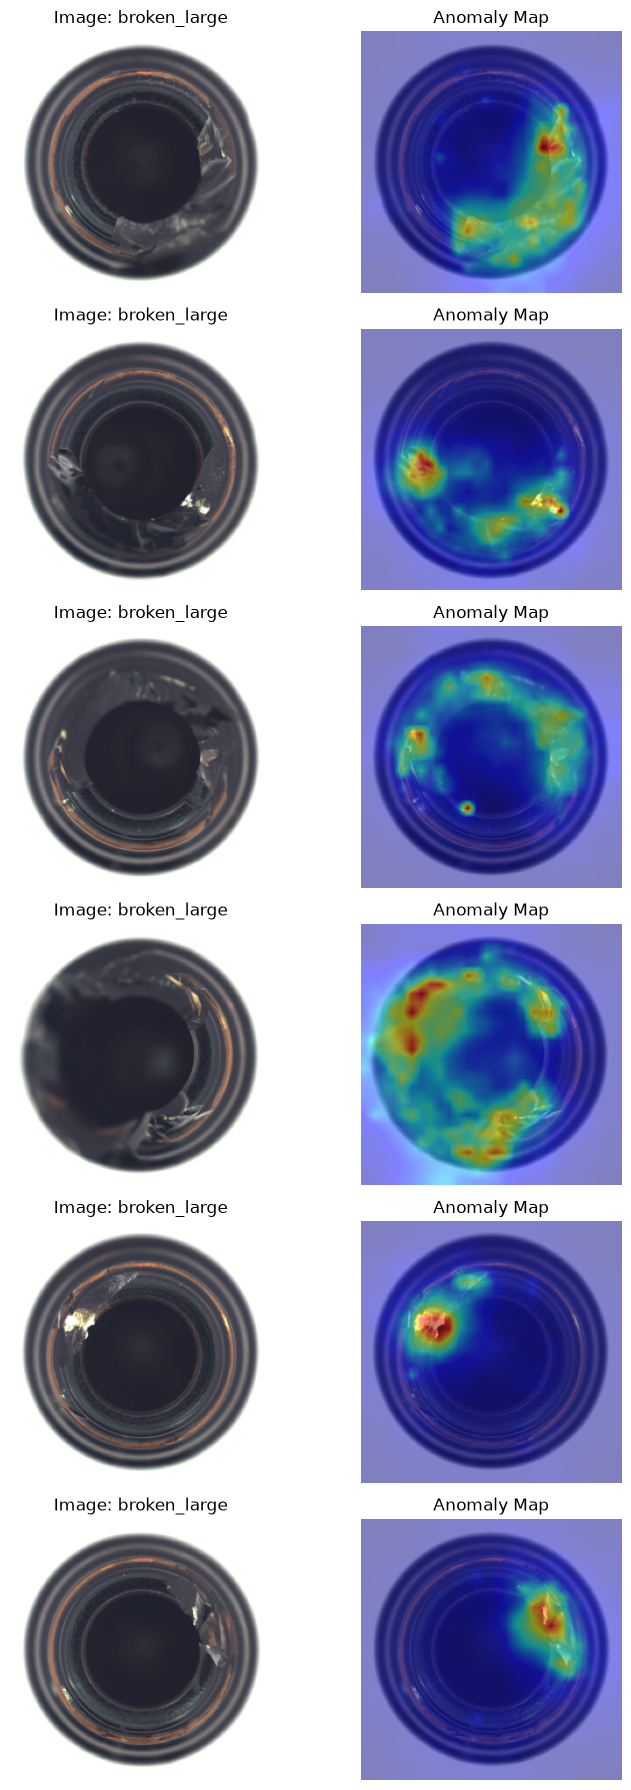

In [6]:
# ==========================================
# 3.1 LOAD TEST IMAGES
# ==========================================

from torchvision import datasets
from torch.utils.data import DataLoader

# Load all test images, including defective samples
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=preprocess
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Test classes:", test_dataset.classes)
print("Total test images:", len(test_dataset))

# ==========================================
# 3.2 MAHALANOBIS DISTANCE CALCULATION
# ==========================================

# Extract features and calculate anomaly scores
all_test_scores = []
all_test_labels = []
all_test_paths = []

feature_extractor.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        f1, f2, f3 = feature_extractor(images)

        # Align feature maps
        f1 = F.interpolate(f1, size=(FEATURE_SIZE, FEATURE_SIZE),
                           mode="bilinear", align_corners=False)
        f2 = F.interpolate(f2, size=(FEATURE_SIZE, FEATURE_SIZE),
                           mode="bilinear", align_corners=False)
        f3 = F.interpolate(f3, size=(FEATURE_SIZE, FEATURE_SIZE),
                           mode="bilinear", align_corners=False)

        # Combine feature maps
        combined = torch.cat([f1, f2, f3], dim=1)
        combined = combined.permute(0, 2, 3, 1)
        combined = combined.reshape(
            combined.shape[0], FEATURE_SIZE * FEATURE_SIZE, -1
        )

        features = combined.cpu().numpy()[:, :, selected_channels]

        # Calculate Mahalanobis distance at each position
        differences = features - mean_vectors[np.newaxis, :, :]

        distances_squared = np.einsum(
            "npd,pde,npe->np",
            differences,
            inverse_covariances,
            differences,
            optimize=True
        )

        distances = np.sqrt(np.maximum(distances_squared, 0))

        # Save pixel-level anomaly maps and image labels
        all_test_scores.append(
            distances.reshape(-1, FEATURE_SIZE, FEATURE_SIZE)
        )
        all_test_labels.extend(labels.numpy())

all_test_scores = np.concatenate(all_test_scores, axis=0)
all_test_labels = np.array(all_test_labels)

# Recover image paths in the same order as the test loader
all_test_paths = [path for path, _ in test_dataset.samples]

print("Anomaly maps shape:", all_test_scores.shape)
print("Test labels shape:", all_test_labels.shape)

# ==========================================
# 3.3 ANOMALY MAP VISUALIZATION
# ==========================================

# Display anomaly maps for representative test images
num_images = min(6, len(test_dataset))

fig, axes = plt.subplots(num_images, 2, figsize=(8, 3 * num_images))

if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_images):
    image = Image.open(all_test_paths[i]).convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    # Normalize the map for visualization
    anomaly_map = all_test_scores[i]
    anomaly_map = (
        (anomaly_map - anomaly_map.min()) /
        (anomaly_map.max() - anomaly_map.min() + 1e-8)
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Image: {test_dataset.classes[all_test_labels[i]]}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image)
    axes[i, 1].imshow(
        anomaly_map,
        cmap="jet",
        alpha=0.5,
        interpolation="bilinear",
        extent=(0, IMG_SIZE, IMG_SIZE, 0)
    )
    axes[i, 1].set_title("Anomaly Map")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [8]:
# ==========================================
# 3.4 IMAGE-LEVEL ANOMALY SCORES
# ==========================================

# Use the maximum distance as each image's anomaly score
image_scores = all_test_scores.reshape(len(test_dataset), -1).max(axis=1)

# Identify normal images by their class name
normal_class_index = test_dataset.class_to_idx["good"]
is_normal = all_test_labels == normal_class_index

print("Normal images:", is_normal.sum())
print("Defective images:", (~is_normal).sum())

# Compare average anomaly scores
print("Mean normal score:", image_scores[is_normal].mean())
print("Mean defective score:", image_scores[~is_normal].mean())

# ==========================================
# 3.5 ANOMALY THRESHOLD AND CLASSIFICATION
# ==========================================

# Set a threshold using the 95th percentile of normal image scores
threshold = np.percentile(image_scores[is_normal], 95)

# Classify images using the threshold
predictions = image_scores > threshold

# Calculate basic classification metrics
true_positives = np.sum(predictions & ~is_normal)
true_negatives = np.sum(~predictions & is_normal)
false_positives = np.sum(predictions & is_normal)
false_negatives = np.sum(~predictions & ~is_normal)

accuracy = (true_positives + true_negatives) / len(is_normal)
precision = true_positives / max(true_positives + false_positives, 1)
recall = true_positives / max(true_positives + false_negatives, 1)

print(f"Threshold: {threshold:.4f}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

Normal images: 20
Defective images: 63
Mean normal score: 34.84498
Mean defective score: 194.2422
Threshold: 58.1728
Accuracy:  0.9759
Precision: 0.9841
Recall:    0.9841


### Analysis

The model successfully generated anomaly maps that highlighted suspicious regions in defective bottles. The mean anomaly score was 194.24 for defective images, compared with 34.84 for normal images. Using a threshold of 58.17, the model achieved 97.59% accuracy, 98.41% precision, and 98.41% recall on the test set. These results indicate strong separation between normal and defective samples, although the threshold was estimated using normal test images, so the evaluation should be interpreted with caution.

# 4. 

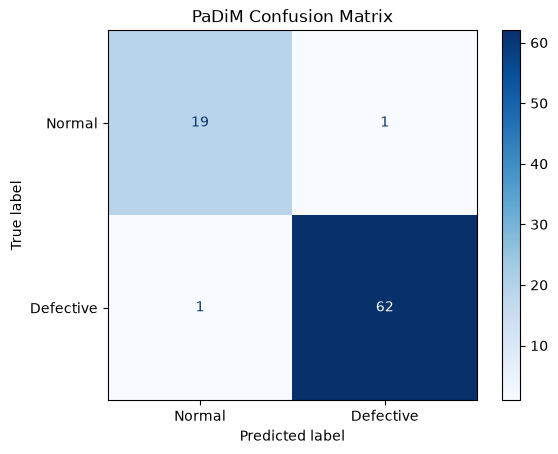

In [ ]:
# ==========================================
# 4.1 CONFUSION MATRIX
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compare actual labels with predicted labels
cm = confusion_matrix(
    ~is_normal,
    predictions,
    labels=[False, True]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Defective"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("PaDiM Confusion Matrix")
plt.show()

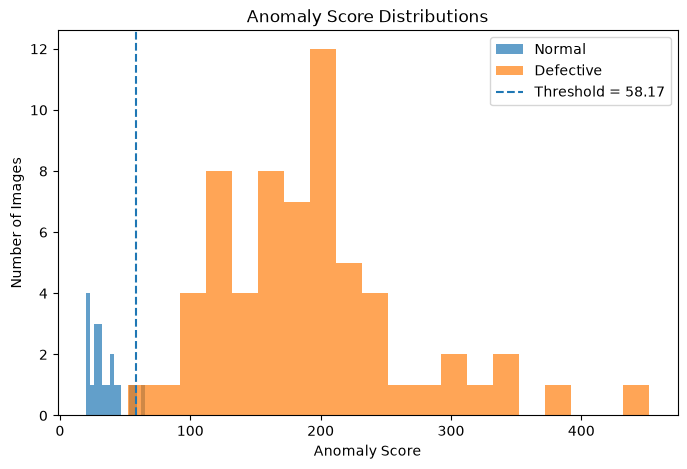

In [10]:
# ==========================================
# 4.2 ANOMALY SCORE DISTRIBUTIONS
# ==========================================

# Compare scores for normal and defective images
plt.figure(figsize=(8, 5))

plt.hist(
    image_scores[is_normal],
    bins=15,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    image_scores[~is_normal],
    bins=20,
    alpha=0.7,
    label="Defective"
)

plt.axvline(
    threshold,
    linestyle="--",
    label=f"Threshold = {threshold:.2f}"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Images")
plt.title("Anomaly Score Distributions")
plt.legend()
plt.show()

In [11]:
# ==========================================
# 4.3 EVALUATION SUMMARY
# ==========================================

print("PaDiM Evaluation Results")
print("-" * 35)
print(f"Threshold: {threshold:.4f}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"True Positives:  {true_positives}")
print(f"True Negatives:  {true_negatives}")
print(f"False Positives: {false_positives}")
print(f"False Negatives: {false_negatives}")

PaDiM Evaluation Results
-----------------------------------
Threshold: 58.1728
Accuracy:  0.9759
Precision: 0.9841
Recall:    0.9841
True Positives:  62
True Negatives:  19
False Positives: 1
False Negatives: 1


### Analysis

The confusion matrix shows that PaDiM correctly classified 81 out of 83 test images, achieving an accuracy of 97.59%. It correctly identified 62 defective images and 19 normal images, with only one false positive and one false negative. Both precision and recall reached 98.41%, indicating strong anomaly detection performance with few classification errors.

The anomaly score distribution also shows a clear separation between normal and defective samples. Normal images generally have lower scores, while defective images exhibit substantially higher scores. The threshold of 58.17 separates most samples correctly, although a small overlap explains the two misclassifications.

Overall, PaDiM demonstrated promising results in detecting bottle defects and identifying suspicious regions. However, the threshold was calculated using normal images from the test set, which introduces a limitation in the evaluation methodology. Therefore, the reported metrics should be interpreted cautiously and ideally confirmed using a threshold determined exclusively from training or validation data.

## Conclusions

In this laboratory, PaDiM was implemented using a pretrained ResNet-18 backbone to detect anomalies in the MVTec AD Bottle dataset. Features from three convolutional layers were used to model normal patterns through mean vectors and covariance matrices. Mahalanobis distance was then applied to generate anomaly maps and classify test images.

The model achieved an accuracy of 97.59%, with 98.41% precision and 98.41% recall, correctly classifying 81 out of 83 test images. The anomaly maps also highlighted suspicious regions in defective bottles, demonstrating the potential of PaDiM for both anomaly detection and localization.

Despite these promising results, the evaluation has a limitation because the anomaly threshold was determined using normal test images. Future improvements should establish the threshold using training or validation data and evaluate the model on an independent test set. Overall, this laboratory demonstrated how pretrained CNN features and statistical modeling can be combined for unsupervised industrial anomaly detection.